# GRN 3: Transformer training, calibration and evaluation

This notebook compares predictive-only training, end-to-end calibration-aware training, and post-hoc calibration (Temperature scaling: parametric, one fitted temperature and Isotonic regression: non-parametric monotone recalibration) on the prepared SERGIO and/or DREAM5 pair datasets. It uses **three seeds** and runs the **same full settings for both small and medium architectures**.

The objective is
$$
\mathcal L_\lambda=(1-\lambda)\,\widetilde{\mathcal C}_{\mathrm{soft}}+\lambda \mathcal L_{\mathrm{base}},
$$
where `lambda=1` is predictive-only training. The smooth calibration penalty is an ECE-style differentiable surrogate, not the canonical ECE metric. Post-hoc calibrators are fitted on validation predictions only.


In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive
from google.colab import files

In [2]:
drive.mount('/content/drive/', force_remount=True)
PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/"
if not os.path.isdir(PROJECT_DIR):
    PROJECT_DIR = os.getcwd()

sys.path.insert(0, PROJECT_DIR)

from grn_experiment_utils import (
    split_indices, train_model, predict, evaluate,
    fit_temperature, apply_temperature, fit_isotonic, apply_isotonic
)

data_dir=os.path.join(PROJECT_DIR,"data")
os.makedirs(data_dir, exist_ok=True)

available = [f for f in ["sergio_pair_data.npz", "dream5_net1_pair_data.npz"]
             if os.path.exists(os.path.join(data_dir, f))]
print("Datasets found:", available)

if not available:
    raise FileNotFoundError(
        "Run Notebook 1 and/or 2 first. Expected files in the project's data/ directory."
    )

# Paired multi-seed experiment. Each seed gets its own split and model initialization;
# within a seed, all methods use the same train/validation/test split.
SEEDS = [42, 123, 2026]
LAMBDAS = [1.0, 0.5, 0.1]
BASE_LOSSES = ["bce", "brier"]
ARCHITECTURES = ["small", "medium"]
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
PATIENCE = 5
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

Mounted at /content/drive/
Datasets found: ['sergio_pair_data.npz', 'dream5_net1_pair_data.npz']


In [3]:
results = []
histories = {}
# Store held-out predictions for reliability diagrams and confidence histograms.
prediction_store = {}

for filename in available:
    d = np.load(os.path.join(data_dir, filename), allow_pickle=True)
    X = d["X"].astype("float32")
    y = d["y"].astype("float32")
    dataset = filename.replace("_pair_data.npz", "")
    print(f"\n{filename}: X={X.shape}, positives={int(y.sum())}/{len(y)}")

    for seed in SEEDS:
        tr, va, te = split_indices(y, seed=seed)
        y_test = y[te].astype(int)

        for architecture in ARCHITECTURES:
            for base_loss in BASE_LOSSES:
                # Fit all three lambda settings for both architectures and both base losses.
                for lam in LAMBDAS:
                    model, hist = train_model(
                        X, y, tr, va, lam=lam, base_loss=base_loss,
                        epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LEARNING_RATE,
                        seed=seed, patience=PATIENCE, model_size=architecture
                    )
                    p_val = predict(model, X[va])
                    p_test = predict(model, X[te])
                    method = "predictive_only" if lam == 1.0 else "end_to_end"
                    row = {
                        "dataset": dataset, "seed": seed, "architecture": architecture,
                        "base_loss": base_loss, "lambda": lam, "method": method
                    }
                    row.update(evaluate(y_test, p_test))
                    results.append(row)
                    histories[(filename, seed, architecture, base_loss, lam)] = hist

                    # Only BCE-based methods are used in the recommended reliability /
                    # confidence plots, but all base-loss results are retained in metrics.
                    if base_loss == "bce":
                        prediction_store[(dataset, seed, architecture, "predictive_only" if lam == 1.0 else f"end_to_end_lambda_{lam:g}")] = (y_test.copy(), p_test.copy())

                    # Post-hoc calibration is fitted only on validation predictions from
                    # the predictive-only model, never on test labels or test predictions.
                    if lam == 1.0:
                        T = fit_temperature(y[va], p_val)
                        p_temp = apply_temperature(p_test, T)
                        row2 = {
                            "dataset": dataset, "seed": seed, "architecture": architecture,
                            "base_loss": base_loss, "lambda": lam,
                            "method": "temperature_scaling", "temperature": T
                        }
                        row2.update(evaluate(y_test, p_temp))
                        results.append(row2)

                        iso = fit_isotonic(y[va], p_val)
                        p_iso = apply_isotonic(p_test, iso)
                        row3 = {
                            "dataset": dataset, "seed": seed, "architecture": architecture,
                            "base_loss": base_loss, "lambda": lam,
                            "method": "isotonic_regression"
                        }
                        row3.update(evaluate(y_test, p_iso))
                        results.append(row3)

                        if base_loss == "bce":
                            prediction_store[(dataset, seed, architecture, "temperature_scaling")] = (y_test.copy(), p_temp.copy())
                            prediction_store[(dataset, seed, architecture, "isotonic_regression")] = (y_test.copy(), p_iso.copy())

        print(f"  completed seed {seed} for {dataset}")

results_df = pd.DataFrame(results)
summary_df = (
    results_df.groupby(["dataset", "architecture", "base_loss", "method", "lambda"], dropna=False)
    .agg({m: ["mean", "std"] for m in ["AUROC", "AUPR", "Brier", "ECE10"]})
    .round(4)
)
display(summary_df)
results_df.to_csv(os.path.join(data_dir, "grn_metrics_multiseed.csv"), index=False)
results_df.to_excel(os.path.join(data_dir, "grn_metrics_multiseed.xlsx"), index=False)
summary_df.to_csv(os.path.join(data_dir, "grn_metrics_multiseed_summary.csv"))
summary_df.to_excel(os.path.join(data_dir, "grn_metrics_multiseed_summary.xlsx"))

# Keep the held-out predictions for reproducible diagnostics / figure regeneration.
prediction_rows = []
for (dataset, seed, architecture, method), (yy, pp) in prediction_store.items():
    prediction_rows.extend({
        "dataset": dataset, "seed": seed, "architecture": architecture,
        "method": method, "y_true": int(yi), "p_pred": float(pi)
    } for yi, pi in zip(yy, pp))
predictions_df = pd.DataFrame(prediction_rows)
predictions_df.to_csv(os.path.join(data_dir, "grn_test_predictions_multiseed.csv"), index=False)
predictions_df.to_excel(os.path.join(data_dir, "grn_test_predictions_multiseed.xlsx"), index=False)

print(f"Saved {len(results_df)} metric rows and {len(predictions_df)} held-out prediction rows.")


sergio_pair_data.npz: X=(5000, 64, 2), positives=303/5000


/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_

  completed seed 42 for sergio


/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_

  completed seed 123 for sergio


...

  completed seed 123 for dream5_net1


/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_experiment_utils.py:82: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder=nn.TransformerEncoder(enc_layer, num_layers=layers)
/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/GRN_Calibration_Experiments/grn_

  completed seed 2026 for dream5_net1


AUROC          \
                                                                 mean     std   
dataset     architecture base_loss method              lambda                   
dream5_net1 medium       bce       end_to_end          0.1     0.8291  0.0201   
                                                       0.5     0.8819  0.0237   
                                   isotonic_regression 1.0     0.8550  0.0326   
                                   predictive_only     1.0     0.8570  0.0321   
                                   temperature_scaling 1.0     0.8570  0.0321   
                         brier     end_to_end          0.1     0.6990  0.0447   
                                                       0.5     0.8454  0.0287   
                                   isotonic_regression 1.0     0.8707  0.0172   
                                   predictive_only     1.0     0.8723  0.0178   
                                   temperature_scaling 1.0     0.8723  0.0178   
            small        bce       end_to_end          0.1     0.7943  0.0088   
                                                       0.5     0.8164  0.0109   
                                   isotonic_regression 1.0     0.8298  0.0133   
                                   predictive_only     1.0     0.8330  0.0149   
                                   temperature_scaling 1.0     0.8330  0.0149   
                         brier     end_to_end          0.1     0.7404  0.0425   
                                                       0.5     0.7994  0.0161   
                                   isotonic_regression 1.0     0.8248  0.0204   
                                   predictive_only     1.0     0.8262  0.0214   
                                   temperature_scaling 1.0     0.8262  0.0214   
sergio      medium       bce       end_to_end          0.1     0.5902  0.0370   
                                                       0.5     0.6111  0.0193   
                                   isotonic_regression 1.0     0.6135  0.0163   
                                   predictive_only     1.0     0.6287  0.0061   
                                   temperature_scaling 1.0     0.6287  0.0061   
                         brier     end_to_end          0.1     0.5647  0.0522   
                                                       0.5     0.5892  0.0376   
                                   isotonic_regression 1.0     0.6042  0.0030   
                                   predictive_only     1.0     0.6226  0.0036   
                                   temperature_scaling 1.0     0.6226  0.0036   
            small        bce       end_to_end          0.1     0.6139  0.0194   
                                                       0.5     0.6223  0.0062   
                                   isotonic_regression 1.0     0.6200  0.0075   
                                   predictive_only     1.0     0.6201  0.0051   
                                   temperature_scaling 1.0     0.6201  0.0051   
                         brier     end_to_end          0.1     0.5649  0.0438   
                                                       0.5     0.5834  0.0482   
                                   isotonic_regression 1.0     0.5799  0.0566   
                                   predictive_only     1.0     0.5956  0.0485   
                                   temperature_scaling 1.0     0.5956  0.0485   

                                                                 AUPR          \
                                                                 mean     std   
dataset     architecture base_loss method              lambda                   
dream5_net1 medium       bce       end_to_end          0.1     0.7474  0.0376   
                                                       0.5     0.8327  0.0327   
                                   isotonic_regression 1.0     0.7645  0.0588   
                                   predictive_only     1.0     0.7872  0.0517   
             

Saved 120 metric rows and 76500 held-out prediction rows.


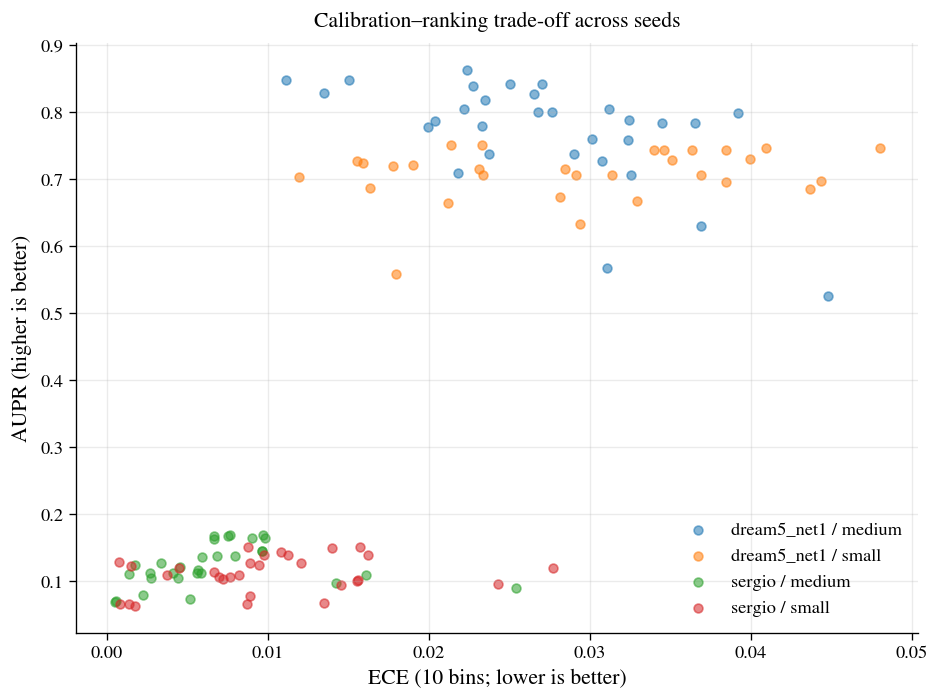

/tmp/ipykernel_1693/1978382409.py:62: RuntimeWarning: Mean of empty slice
  mx = np.nanmean(np.asarray(seed_x), axis=0)
/tmp/ipykernel_1693/1978382409.py:63: RuntimeWarning: Mean of empty slice
  my = np.nanmean(np.asarray(seed_y), axis=0)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


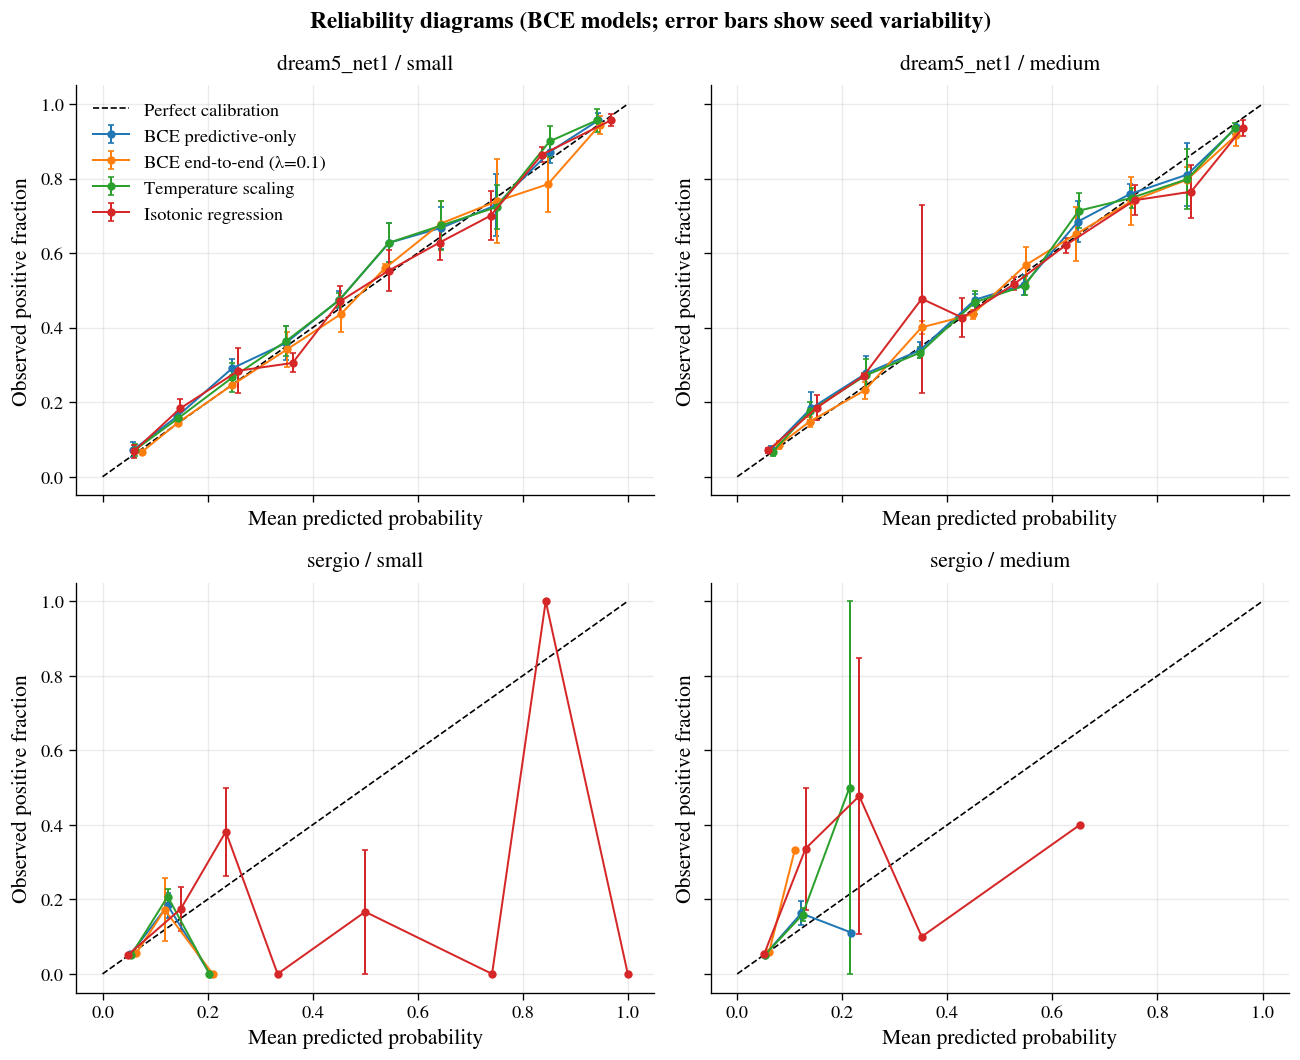

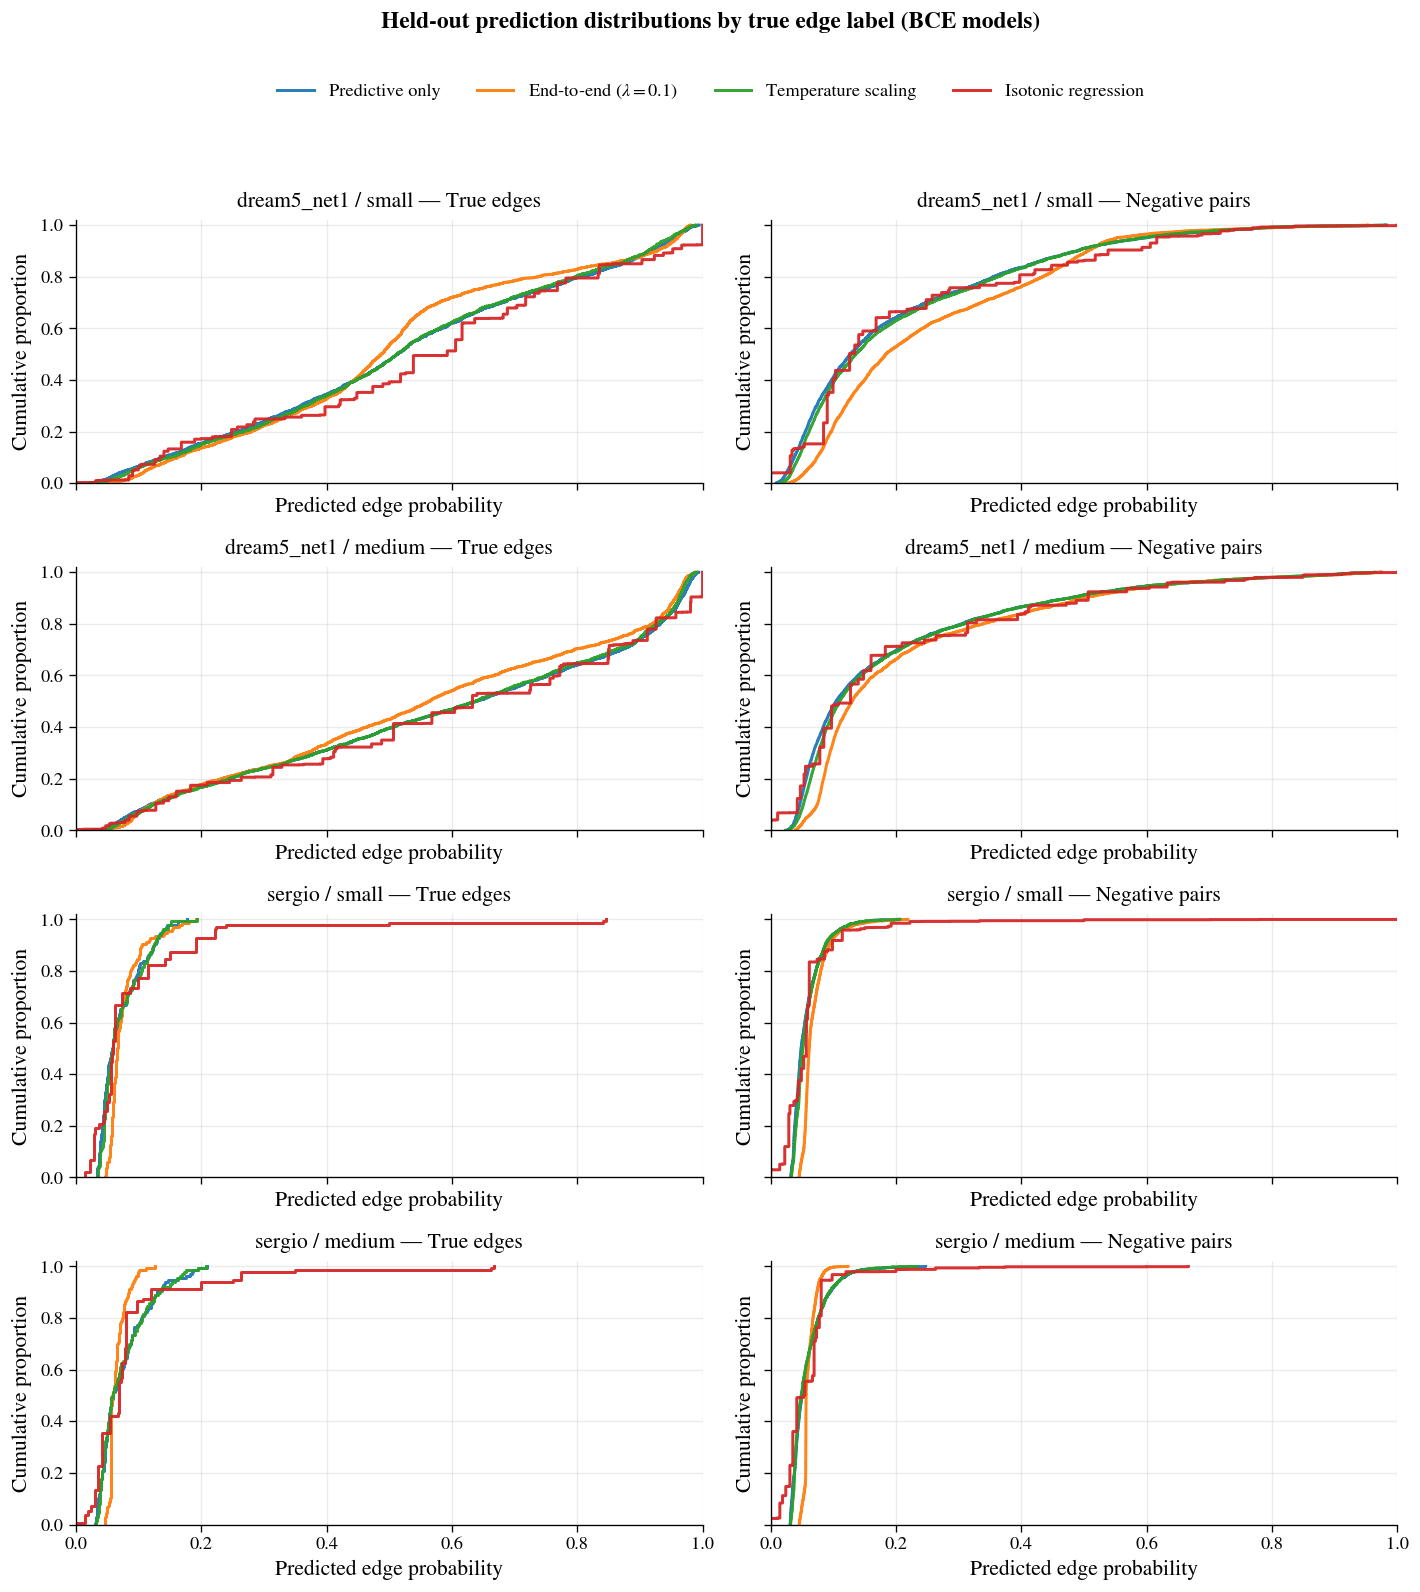

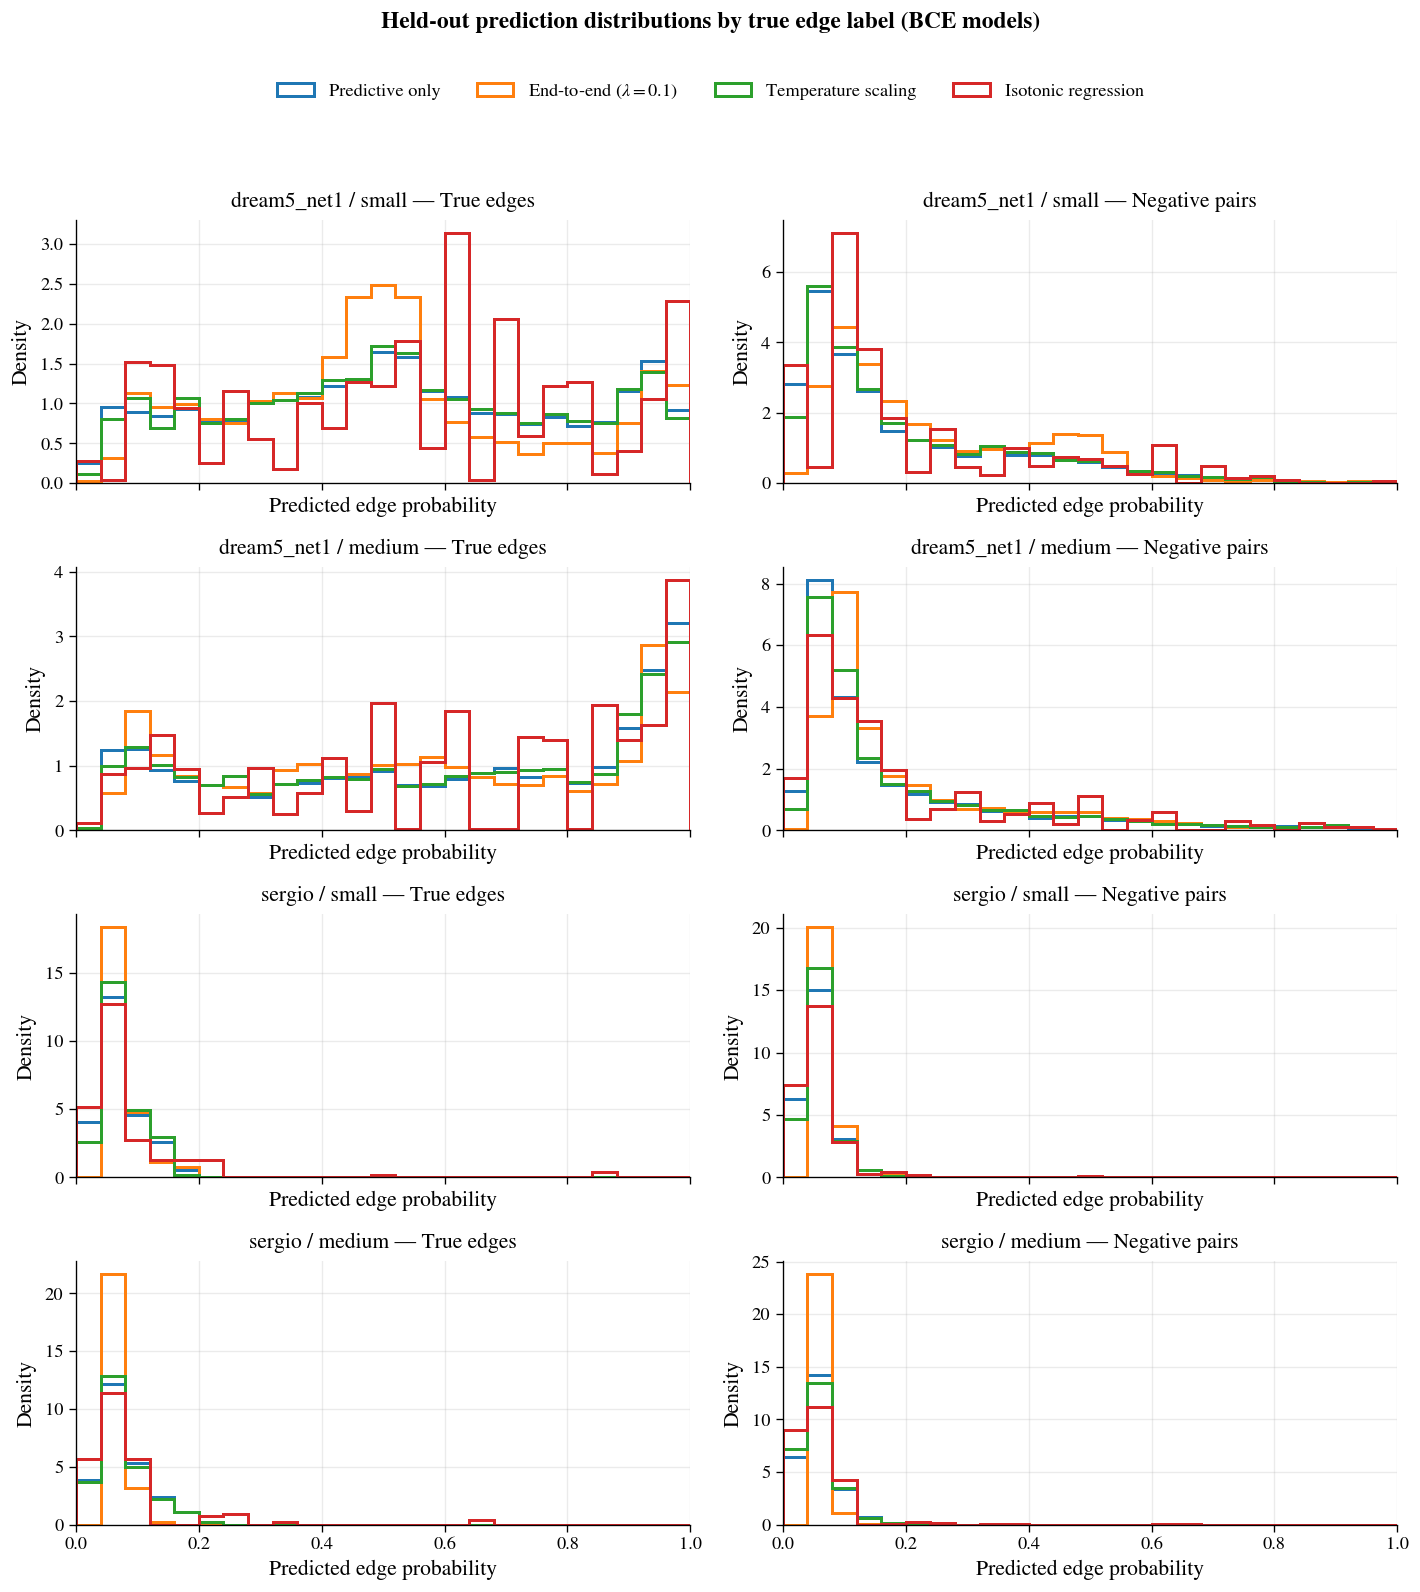

In [4]:
# Figure 1: AUPR versus ECE10, with one point per seed-level evaluation.
# This preserves the calibration/ranking trade-off and makes seed variability visible.
fig, ax = plt.subplots(figsize=(8, 6))
for (dataset, architecture), group in results_df.groupby(["dataset", "architecture"]):
    ax.scatter(group["ECE10"], group["AUPR"], alpha=0.55, s=28,
               label=f"{dataset} / {architecture}")
ax.set_xlabel("ECE (10 bins; lower is better)", labelpad=4)
ax.set_ylabel("AUPR (higher is better)", labelpad=5)
ax.set_title("Calibration–ranking trade-off across seeds", pad=10)
ax.legend(frameon=False, loc="best")
ax.grid(alpha=0.25)
ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()
fig.savefig(os.path.join(data_dir, "Figure_GRN3_AUPR_vs_ECE.pdf"), format="pdf", bbox_inches="tight")
plt.show()

# Figure 2: reliability diagrams, one panel per dataset × architecture.
# The four plotted methods use the BCE base loss to keep the comparison readable.
def reliability_points(y_true, p_pred, bins=10):
    edges = np.linspace(0.0, 1.0, bins + 1)
    xs, ys = [], []
    for j in range(bins):
        mask = ((p_pred >= edges[j]) &
                (p_pred < edges[j + 1] if j < bins - 1 else p_pred <= edges[j + 1]))
        if mask.any():
            xs.append(float(np.mean(p_pred[mask])))
            ys.append(float(np.mean(y_true[mask])))
    return np.asarray(xs), np.asarray(ys)

methods_for_plots = [
    ("predictive_only", "BCE predictive-only"),
    ("end_to_end_lambda_0.1", "BCE end-to-end (λ=0.1)"),
    ("temperature_scaling", "Temperature scaling"),
    ("isotonic_regression", "Isotonic regression"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
datasets = sorted(results_df["dataset"].unique())
for ax, (dataset, architecture) in zip(
    axes.ravel(), [(ds, ar) for ds in datasets for ar in ARCHITECTURES]
):
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfect calibration")
    for method, label in methods_for_plots:
        seed_x, seed_y = [], []
        for seed in SEEDS:
            key = (dataset, seed, architecture, method)
            if key not in prediction_store:
                continue
            yy, pp = prediction_store[key]
            xx, ybin = reliability_points(yy, pp, bins=10)
            # Bins can be empty for a particular seed; interpolate only for display
            # on common bin centers, leaving absent bins as NaN.
            edges = np.linspace(0, 1, 11)
            xb = np.full(10, np.nan); yb = np.full(10, np.nan)
            for j in range(10):
                mask = ((pp >= edges[j]) &
                        (pp < edges[j+1] if j < 9 else pp <= edges[j+1]))
                if mask.any():
                    xb[j] = pp[mask].mean()
                    yb[j] = yy[mask].mean()
            seed_x.append(xb); seed_y.append(yb)
        if seed_x:
            mx = np.nanmean(np.asarray(seed_x), axis=0)
            my = np.nanmean(np.asarray(seed_y), axis=0)
            sy = np.nanstd(np.asarray(seed_y), axis=0, ddof=0)
            ok = np.isfinite(mx) & np.isfinite(my)
            ax.errorbar(mx[ok], my[ok], yerr=sy[ok], marker="o", markersize=4,
                        linewidth=1.2, capsize=2, label=label)
    ax.set_title(f"{dataset} / {architecture}", pad=10)
    ax.set_xlabel("Mean predicted probability", labelpad=4)
    ax.set_ylabel("Observed positive fraction", labelpad=5)
    ax.grid(alpha=0.25)
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
axes[0, 0].legend(frameon=False, loc="best")
fig.suptitle("Reliability diagrams (BCE models; error bars show seed variability)")
fig.tight_layout()
fig.savefig(os.path.join(data_dir, "Figure_GRN3_Reliability_Diagrams.pdf"), bbox_inches="tight")
plt.show()

# # Figure 3: held-out prediction distributions, split by true edge label.
# # Solid lines are positive pairs; dashed lines are negative pairs.
# fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True)
# colors = {
#     "predictive_only": "C0",
#     "end_to_end_lambda_0.1": "C1",
#     "temperature_scaling": "C2",
#     "isotonic_regression": "C3",
# }
# for ax, (dataset, architecture) in zip(
#     axes.ravel(), [(ds, ar) for ds in datasets for ar in ARCHITECTURES]
# ):
#     subset = predictions_df[
#         (predictions_df["dataset"] == dataset) &
#         (predictions_df["architecture"] == architecture) &
#         (predictions_df["method"].isin(colors))
#     ]
#     for method, color in colors.items():
#         sm = subset[subset["method"] == method]
#         for label_value, linestyle, label_name in [(1, "-", "true edges"), (0, "--", "negative pairs")]:
#             vals = sm.loc[sm["y_true"] == label_value, "p_pred"].to_numpy()
#             if len(vals):
#                 ax.hist(vals, bins=np.linspace(0, 1, 21), density=True, histtype="step",
#                         linewidth=1.6, color=color, linestyle=linestyle,
#                         label=f"{method.replace('_', ' ')} — {label_name}")
#     ax.set_title(f"{dataset} / {architecture}", pad=10)
#     ax.set_xlabel("Predicted edge probability", labelpad=4)
#     ax.set_ylabel("Density", labelpad=5)
#     ax.grid(alpha=0.2)
#     ax.tick_params(axis="both", which="major", length=4, width=0.8)
# axes[0, 0].legend(frameon=False, loc="best")
# fig.suptitle("Held-out prediction distributions by true edge label (BCE models)")
# fig.tight_layout()
# fig.savefig(os.path.join(data_dir, "Figure_GRN3_Confidence_Histograms.pdf"), bbox_inches="tight")
# plt.show()

# Figure 3: Held-out prediction distributions by true edge label.
# ECDFs reduce overlap and make concentrated/discrete predictions easier to compare.

import numpy as np
import matplotlib.pyplot as plt

methods_for_plots = [
    ("predictive_only", "Predictive only", "C0"),
    ("end_to_end_lambda_0.1", "End-to-end ($\\lambda=0.1$)", "C1"),
    ("temperature_scaling", "Temperature scaling", "C2"),
    ("isotonic_regression", "Isotonic regression", "C3"),
]

label_groups = [
    (1, "True edges"),
    (0, "Negative pairs"),
]

panel_pairs = [
    (ds, ar)
    for ds in sorted(predictions_df["dataset"].unique())
    for ar in ARCHITECTURES
]

fig, axes = plt.subplots(
    nrows=len(panel_pairs),
    ncols=2,
    figsize=(12, 3.2 * len(panel_pairs)),
    sharex=True,
    sharey=True,
)

# Ensure axes is consistently two-dimensional.
axes = np.asarray(axes).reshape(len(panel_pairs), 2)

for row, (dataset, architecture) in enumerate(panel_pairs):
    subset = predictions_df[
        (predictions_df["dataset"] == dataset)
        & (predictions_df["architecture"] == architecture)
    ]

    for col, (label_value, label_name) in enumerate(label_groups):
        ax = axes[row, col]

        label_subset = subset[subset["y_true"] == label_value]

        for method, method_label, color in methods_for_plots:
            values = label_subset.loc[
                label_subset["method"] == method, "p_pred"
            ].to_numpy(dtype=float)

            values = values[np.isfinite(values)]

            if len(values) == 0:
                continue

            # Empirical CDF: proportion of predictions <= each probability.
            x = np.sort(values)
            y = np.arange(1, len(x) + 1) / len(x)

            # Include the starting point so the curve begins at zero.
            x_ecdf = np.concatenate(([x[0]], x))
            y_ecdf = np.concatenate(([0.0], y))

            ax.step(
                x_ecdf,
                y_ecdf,
                where="post",
                color=color,
                linewidth=1.8,
                alpha=0.95,
                label=method_label,
            )

        ax.set_title(
            f"{dataset} / {architecture} — {label_name}",
            pad=8,
        )
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("Predicted edge probability", labelpad=4)
        ax.set_ylabel("Cumulative proportion", labelpad=5)
        ax.grid(alpha=0.25)
        ax.tick_params(axis="both", which="major", length=4, width=0.8)

# One shared legend, avoiding repetition in every panel.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=4,
    frameon=False,
)

fig.suptitle(
    "Held-out prediction distributions by true edge label (BCE models)",
    y=1.035,
    fontweight="bold",
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    os.path.join(data_dir, "Figure_GRN3_Confidence_ECDF.pdf"),
    format="pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# Figure 3: Held-out prediction distributions by true edge label.
# Overlaid density histograms, separated into true edges and negative pairs.

import numpy as np
import matplotlib.pyplot as plt
import os

methods_for_plots = [
    ("predictive_only", "Predictive only", "C0"),
    ("end_to_end_lambda_0.1", r"End-to-end ($\lambda=0.1$)", "C1"),
    ("temperature_scaling", "Temperature scaling", "C2"),
    ("isotonic_regression", "Isotonic regression", "C3"),
]

label_groups = [
    (1, "True edges"),
    (0, "Negative pairs"),
]

panel_pairs = [
    (ds, ar)
    for ds in sorted(predictions_df["dataset"].unique())
    for ar in ARCHITECTURES
]

# Shared bins ensure comparisons across methods and panels are consistent.
bins = np.linspace(0, 1, 26)  # 25 bins, width = 0.04

fig, axes = plt.subplots(
    nrows=len(panel_pairs),
    ncols=2,
    figsize=(12, 3.2 * len(panel_pairs)),
    sharex=True,
    sharey=False,
)

axes = np.asarray(axes).reshape(len(panel_pairs), 2)

for row, (dataset, architecture) in enumerate(panel_pairs):
    subset = predictions_df[
        (predictions_df["dataset"] == dataset)
        & (predictions_df["architecture"] == architecture)
    ]

    for col, (label_value, label_name) in enumerate(label_groups):
        ax = axes[row, col]
        label_subset = subset[subset["y_true"] == label_value]

        for method, method_label, color in methods_for_plots:
            values = label_subset.loc[
                label_subset["method"] == method, "p_pred"
            ].to_numpy(dtype=float)

            values = values[np.isfinite(values)]

            if len(values) == 0:
                continue

            ax.hist(
                values,
                bins=bins,
                density=True,
                histtype="step",
                linewidth=1.8,
                color=color,
                label=method_label,
            )

        ax.set_title(
            f"{dataset} / {architecture} — {label_name}",
            pad=8,
        )
        ax.set_xlim(0, 1)
        ax.set_xlabel("Predicted edge probability", labelpad=4)
        ax.set_ylabel("Density", labelpad=5)
        ax.grid(alpha=0.25)
        ax.tick_params(axis="both", which="major", length=4, width=0.8)

# Shared legend.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=4,
    frameon=False,
)

fig.suptitle(
    "Held-out prediction distributions by true edge label (BCE models)",
    y=1.035,
    fontweight="bold",
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    os.path.join(data_dir, "Figure_GRN3_Confidence_Histograms.pdf"),
    format="pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)